# GreenBox AI – Dados de estufa (IoT Agriculture 2024)

Este notebook usa um dataset de uma **estufa real** para as duas linhas de IA da GreenBox:

- **Parte A – Previsão do consumo energético (RF13):** o dataset não tem consumo medido, mas tem o estado dos atuadores (ventoinha e bombas). Multiplicando o tempo ligado pela **potência típica** dos equipamentos da GreenBox, obtém-se um **consumo estimado de estufa**, que depois se tenta prever para as 24 horas seguintes.
- **Parte B – Deteção de anomalias na rega (RF15 e RF04):** verificar se a humidade sobe depois de regar e se a bomba de rega funciona com o depósito vazio.

**Dataset:** [IoT Agriculture 2024](https://www.kaggle.com/datasets/wisam1985/iot-agriculture-2024) (Kaggle), ficheiro `IoTProcessed_Data.csv` na pasta `ia/dados/`. Confirmar a licença na página do Kaggle antes de o redistribuir.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Funciona quer o notebook corra a partir da pasta ia/ quer da raiz do projeto
PASTA_DADOS = next((p for p in [Path("dados"), Path("ia/dados")] if p.is_dir()), Path("dados"))
FICHEIRO = PASTA_DADOS / "IoTProcessed_Data.csv"
SEMENTE = 42

## 1. Carregar e limpar os dados

Problemas encontrados no ficheiro original:

| Problema | Tratamento |
|---|---|
| Linhas fora de ordem cronológica | Ordenar por data |
| ~9 200 datas repetidas com valores diferentes | Agrupar por data e usar a média |
| Humidade = 0 (leituras falhadas) | Marcar como valor em falta |
| N, P e K saturados em 255 em ~70 % das leituras | Não usar estas colunas |
| Atuadores em duas colunas (`_ON` e `_OFF`) | Usar só a coluna `_ON` (1 = ligado) |
| Buracos no tempo (até ~11 dias) | Não interpolar buracos longos; as horas sem dados ficam de fora |

**Interpretação da coluna `humidity`:** a rega liga quando o valor desce abaixo de ~40 % e o valor sobe depois de regar, por isso é tratada como **humidade do substrato**.

In [2]:
bruto = pd.read_csv(FICHEIRO, parse_dates=["date"])
print("Linhas originais:", len(bruto))

dados = (bruto.dropna(subset=["date"])
              .rename(columns={"date": "data_hora", "tempreature": "temperatura", "humidity": "humidade",
                               "water_level": "nivel_agua", "Fan_actuator_ON": "ventoinha",
                               "Watering_plant_pump_ON": "bomba_rega",
                               "Water_pump_actuator_ON": "bomba_deposito"})
              [["data_hora", "temperatura", "humidade", "nivel_agua", "ventoinha", "bomba_rega", "bomba_deposito"]]
              .groupby("data_hora").mean()
              .sort_index())
dados.loc[dados["humidade"] <= 0, "humidade"] = np.nan

print("Linhas depois da limpeza:", len(dados))
print("Período:", dados.index.min(), "até", dados.index.max())
dados.describe().round(1)

Linhas originais: 37922
Linhas depois da limpeza: 28682
Período: 2023-11-27 06:26:00 até 2024-03-30 05:24:00


,temperatura,humidade,nivel_agua,ventoinha,bomba_rega,bomba_deposito
count,28682.0,28509.0,28682.0,28682.0,28682.0,28682.0
mean,17.8,57.9,88.1,0.2,0.1,0.1
std,6.8,15.3,27.7,0.4,0.3,0.3
min,3.0,0.1,0.0,0.0,0.0,0.0
25%,13.0,58.0,100.0,0.0,0.0,0.0
50%,16.0,60.0,100.0,0.0,0.0,0.0
75%,22.0,64.0,100.0,0.2,0.0,0.0
max,41.0,100.0,100.0,1.0,1.0,1.0


### Como funciona o controlo nesta estufa

Antes de modelar, vale a pena perceber as regras que a estufa original seguia.

In [3]:
print("Ventoinha ligada, por temperatura (°C):")
print(dados.groupby(pd.cut(dados["temperatura"], [0, 15, 20, 25, 30, 45]), observed=True)["ventoinha"].mean().round(2))
print("\nBomba de rega ligada, por humidade (%):")
print(dados.groupby(pd.cut(dados["humidade"], [0, 20, 40, 60, 80, 100]), observed=True)["bomba_rega"].mean().round(2))

Ventoinha ligada, por temperatura (°C):
temperatura
(0, 15]     0.00
(15, 20]    0.00
(20, 25]    0.58
(25, 30]    1.00
(30, 45]    1.00
Name: ventoinha, dtype: float64

Bomba de rega ligada, por humidade (%):
humidade
(0, 20]      1.00
(20, 40]     1.00
(40, 60]     0.04
(60, 80]     0.00
(80, 100]    0.00
Name: bomba_rega, dtype: float64


# Parte A – Previsão do consumo energético

## 2. Consumo estimado com potências típicas

O dataset não tem consumo medido. O consumo é **estimado** a partir do tempo que cada equipamento esteve ligado, com **potências típicas** dos componentes da GreenBox:

| Equipamento | Potência típica | Origem do estado |
|---|---|---|
| Ventilação (2 ventoinhas de 12 V) | 6 W | `ventoinha` do dataset |
| Bomba de rega (12 V) | 15 W | `bomba_rega` do dataset |
| Bomba do depósito (12 V) | 15 W | `bomba_deposito` do dataset |
| Iluminação LED de cultivo | 18 W | Não existe no dataset: horário da cultura de referência (16 h de luz, das 06:00 às 22:00) |

> **Estes valores são aproximados.** Quando o hardware da GreenBox estiver montado, substituí-los pelas potências medidas com os INA219.

In [4]:
POTENCIAS_W = {"ventoinha": 6, "bomba_rega": 15, "bomba_deposito": 15, "led": 18}
HORARIO_LED = (6, 22)   # liga às 06:00 e desliga às 22:00

# Agregação horária: fração de cada hora em que cada equipamento esteve ligado
por_hora = dados.resample("1h").mean()
por_hora["led"] = ((por_hora.index.hour >= HORARIO_LED[0]) & (por_hora.index.hour < HORARIO_LED[1])).astype(float)

# Energia (Wh) = potência (W) × fração da hora ligada × 1 h
por_hora["consumo_wh"] = sum(por_hora[eq] * p for eq, p in POTENCIAS_W.items())
por_hora.loc[por_hora["temperatura"].isna(), "consumo_wh"] = np.nan   # horas sem leituras ficam sem consumo

print(f"Horas com dados: {por_hora['consumo_wh'].notna().sum()} de {len(por_hora)}")
por_hora[["temperatura", "humidade", "ventoinha", "bomba_rega", "led", "consumo_wh"]].describe().round(2)

Horas com dados: 2163 de 2976


,temperatura,humidade,ventoinha,bomba_rega,led,consumo_wh
count,2163.00,2151.00,2163.00,2163.00,2976.00,2163.00
mean,17.46,60.27,0.24,0.07,0.67,15.81
std,6.63,11.34,0.40,0.24,0.47,9.49
min,3.00,1.00,0.00,0.00,0.00,0.00
25%,12.58,58.56,0.00,0.00,0.00,6.00
50%,15.67,59.83,0.00,0.00,1.00,18.00
75%,22.13,64.71,0.42,0.00,1.00,18.00
max,36.83,100.00,1.00,1.00,1.00,54.00


## 3. Fonte de dados externa: meteorologia da Open-Meteo

O briefing pede pelo menos uma **fonte de dados adicional**. A estufa do dataset fica na Tikrit University (Iraque), por isso vai-se buscar o **histórico meteorológico horário** desse local e dessas datas à [Open-Meteo](https://open-meteo.com/) (gratuita, sem chave).

O resultado fica guardado em `ia/dados/open_meteo_tikrit.csv`, para não repetir o pedido. Se não houver Internet, o notebook continua sem estas variáveis.

In [5]:
CACHE_METEO = PASTA_DADOS / "open_meteo_tikrit.csv"
LAT, LON = 34.61, 43.68   # Tikrit, Iraque

def carregar_meteo(inicio, fim):
    if CACHE_METEO.exists():
        return pd.read_csv(CACHE_METEO, parse_dates=["data_hora"], index_col="data_hora")
    url = ("https://archive-api.open-meteo.com/v1/archive"
           f"?latitude={LAT}&longitude={LON}&start_date={inicio}&end_date={fim}"
           "&hourly=temperature_2m,relative_humidity_2m,shortwave_radiation&timezone=Asia%2FBaghdad")
    bruto = pd.read_json(url)["hourly"]
    meteo = pd.DataFrame({
        "data_hora": pd.to_datetime(bruto["time"]),
        "temp_exterior": bruto["temperature_2m"],
        "humidade_exterior": bruto["relative_humidity_2m"],
        "radiacao_solar": bruto["shortwave_radiation"],
    }).set_index("data_hora")
    meteo.to_csv(CACHE_METEO)
    return meteo

try:
    meteo = carregar_meteo(por_hora.index.min().date(), por_hora.index.max().date())
    por_hora = por_hora.join(meteo)
    VARIAVEIS_METEO = list(meteo.columns)
    print("Meteorologia da Open-Meteo:", len(meteo), "horas")
except Exception as erro:
    VARIAVEIS_METEO = []
    print("Sem meteorologia externa (sem ligação à Open-Meteo?):", erro)

Meteorologia da Open-Meteo: 3000 horas


## 4. Variáveis e divisão cronológica

Tal como no notebook `previsao_consumo.ipynb`, só se usa informação disponível **no momento da previsão** das 24 horas seguintes: hora do dia, dia da semana, consumo à mesma hora do dia anterior, consumo médio do dia anterior e a meteorologia exterior (que no sistema real vem da **previsão** da Open-Meteo).

In [6]:
modelo_df = por_hora.copy()
modelo_df["hora"] = modelo_df.index.hour
modelo_df["dia_semana"] = modelo_df.index.dayofweek
modelo_df["consumo_lag_24"] = modelo_df["consumo_wh"].shift(24)
modelo_df["consumo_media_24h"] = modelo_df["consumo_wh"].shift(24).rolling(24, min_periods=12).mean()

VARIAVEIS = ["hora", "dia_semana", "consumo_lag_24", "consumo_media_24h"] + VARIAVEIS_METEO
ALVO = "consumo_wh"
modelo_df = modelo_df.dropna(subset=VARIAVEIS + [ALVO])

corte = int(len(modelo_df) * 0.8)
treino, teste = modelo_df.iloc[:corte], modelo_df.iloc[corte:]
print(f"Horas utilizáveis: {len(modelo_df)}")
print(f"Treino: {treino.index.min()} até {treino.index.max()} ({len(treino)} h)")
print(f"Teste:  {teste.index.min()} até {teste.index.max()} ({len(teste)} h)")

Horas utilizáveis: 2066
Treino: 2023-11-28 17:00:00 até 2024-02-11 05:00:00 (1652 h)
Teste:  2024-02-11 06:00:00 até 2024-02-29 05:00:00 (414 h)


C:\Users\claud\AppData\Local\Temp\ipykernel_5368\549035628.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  modelo_df["dia_semana"] = modelo_df.index.dayofweek


## 5. Modelos e avaliação

Os mesmos três modelos do notebook da casa, avaliados com o **MAE** (critério do RF13: erro inferior ao do modelo de referência).

In [7]:
media_por_hora = treino.groupby("hora")[ALVO].mean()
previsoes = {"Referência (média por hora)": teste["hora"].map(media_por_hora).to_numpy()}

modelos = {
    "Regressão linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           random_state=SEMENTE, n_jobs=-1),
}
for nome, modelo in modelos.items():
    modelo.fit(treino[VARIAVEIS], treino[ALVO])
    previsoes[nome] = modelo.predict(teste[VARIAVEIS])

mae_ref = mean_absolute_error(teste[ALVO], previsoes["Referência (média por hora)"])
resultados = pd.DataFrame([
    {"Modelo": nome,
     "MAE (Wh)": mean_absolute_error(teste[ALVO], prev),
     "RMSE (Wh)": mean_squared_error(teste[ALVO], prev) ** 0.5,
     "Melhoria face à referência": 1 - mean_absolute_error(teste[ALVO], prev) / mae_ref}
    for nome, prev in previsoes.items()
]).set_index("Modelo")
resultados.style.format({"MAE (Wh)": "{:.2f}", "RMSE (Wh)": "{:.2f}", "Melhoria face à referência": "{:.1%}"})

,MAE (Wh),RMSE (Wh),Melhoria face à referência
Modelo,,,
Referência (média por hora),2.83,3.59,0.0%
Regressão linear,2.61,3.74,7.9%
Random Forest,1.84,3.26,34.9%


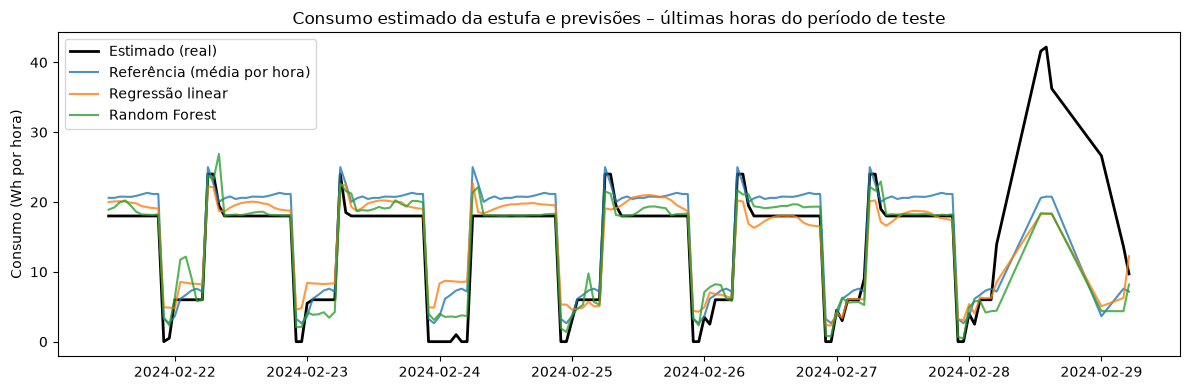

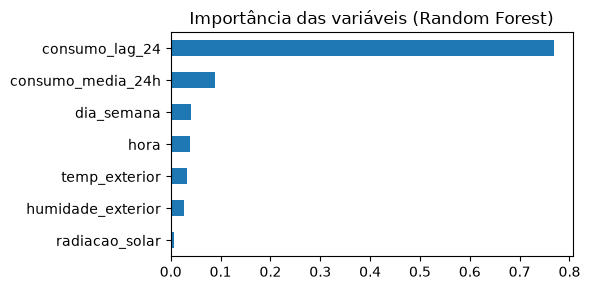

In [8]:
ultimos = teste.index[-24 * 7:]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ultimos, teste.loc[ultimos, ALVO], label="Estimado (real)", color="black", linewidth=2)
for nome, prev in previsoes.items():
    ax.plot(ultimos, pd.Series(prev, index=teste.index).loc[ultimos], label=nome, alpha=0.8)
ax.set_title("Consumo estimado da estufa e previsões – últimas horas do período de teste")
ax.set_ylabel("Consumo (Wh por hora)")
ax.legend()
plt.tight_layout()
plt.show()

importancia = pd.Series(modelos["Random Forest"].feature_importances_, index=VARIAVEIS).sort_values()
importancia.plot.barh(figsize=(6, 3), title="Importância das variáveis (Random Forest)")
plt.tight_layout()
plt.show()

# Parte B – Deteção de anomalias na rega

## 6. Episódios de rega

Um **episódio de rega** é um período contínuo com a bomba de rega ligada. Para cada episódio regista-se a humidade antes de regar, a humidade máxima nos 30 minutos seguintes e o nível do depósito.

In [9]:
JANELA_APOS = pd.Timedelta(minutes=30)
validos = dados.dropna(subset=["humidade"])
ligada = validos["bomba_rega"] >= 0.5
bloco = (ligada != ligada.shift()).cumsum()

episodios = []
for _, ep in validos[ligada].groupby(bloco[ligada]):
    inicio, fim = ep.index[0], ep.index[-1]
    antes = validos.loc[inicio - pd.Timedelta(minutes=15):inicio, "humidade"]
    depois = validos.loc[fim:fim + JANELA_APOS, "humidade"]
    if (fim - inicio) > pd.Timedelta(hours=6) or antes.empty or depois.empty:
        continue
    episodios.append({"inicio": inicio, "duracao_min": (fim - inicio).total_seconds() / 60,
                      "humidade_antes": antes.iloc[0], "humidade_max_depois": depois.max(),
                      "nivel_deposito": ep["nivel_agua"].mean()})

episodios = pd.DataFrame(episodios)
episodios["subida"] = episodios["humidade_max_depois"] - episodios["humidade_antes"]
episodios["deposito_vazio"] = episodios["nivel_deposito"] <= 5
print(f"{len(episodios)} episódios de rega")
print(episodios.groupby("deposito_vazio")["subida"].describe().round(1))

100 episódios de rega
                count  mean   std   min  25%  50%  75%   max
deposito_vazio                                              
False            95.0   5.5  12.7 -41.0  0.0  3.0  8.0  51.0
True              5.0   0.7   2.9  -2.5 -1.2  0.0  2.0   5.0


## 7. Regra de deteção (RF15) e bomba a seco (RF04)

- **Anomalia na rega:** a humidade não sobe pelo menos `LIMIAR` pontos nos 30 minutos seguintes à rega.
- **Bomba a seco:** a bomba de rega liga com o depósito abaixo de 5 %. Na GreenBox, o RF04 impede que isto aconteça.

Para avaliar a regra, consideram-se **falhas reais** os episódios com o depósito vazio (sem água, a rega não pode fazer subir a humidade) e **normais** os restantes. Experimentam-se vários limiares para ver o compromisso entre **detetar as falhas** e **não dar falsos alarmes**.

In [10]:
print("Bomba de rega a funcionar com o depósito vazio:",
      int(episodios["deposito_vazio"].sum()), "de", len(episodios), "episódios")

linhas = []
for limiar in [1, 2, 3, 5, 8, 10]:
    alarme = episodios["subida"] < limiar
    falhas, normais = episodios["deposito_vazio"], ~episodios["deposito_vazio"]
    linhas.append({"Limiar (pontos)": limiar,
                   "Falhas detetadas": (alarme & falhas).sum() / max(falhas.sum(), 1),
                   "Falsos alarmes": (alarme & normais).sum() / max(normais.sum(), 1)})
avaliacao = pd.DataFrame(linhas).set_index("Limiar (pontos)")
avaliacao.style.format("{:.0%}")

Bomba de rega a funcionar com o depósito vazio: 5 de 100 episódios


,Falhas detetadas,Falsos alarmes
Limiar (pontos),,
1,60%,31%
2,60%,38%
3,80%,43%
5,80%,58%
8,100%,73%
10,100%,77%


## 8. Teste com falhas simuladas

Como há poucas falhas reais, simulam-se falhas: para cada episódio normal, cria-se uma cópia em que a humidade **não sobe** (como num tubo obstruído). O critério do RF15 é detetar **pelo menos 90 %** das falhas simuladas.

In [11]:
LIMIAR = 3   # ajustar com base na tabela anterior
normais = episodios[~episodios["deposito_vazio"]].copy()
simuladas = normais.copy()
simuladas["subida"] = np.random.default_rng(SEMENTE).uniform(-1, 1, len(simuladas))   # humidade quase constante

detecao = (simuladas["subida"] < LIMIAR).mean()
falsos_alarmes = (normais["subida"] < LIMIAR).mean()
print(f"Limiar de {LIMIAR} pontos")
print(f"Falhas simuladas detetadas: {detecao:.0%} (critério do RF15: ≥ 90 %)")
print(f"Falsos alarmes em regas normais: {falsos_alarmes:.0%}")

Limiar de 3 pontos
Falhas simuladas detetadas: 100% (critério do RF15: ≥ 90 %)
Falsos alarmes em regas normais: 43%


## Conclusões e próximos passos

- **Parte A:** com o consumo estimado a partir dos atuadores, verifica-se se o Random Forest bate o modelo de referência numa estufa real. Substituir as potências típicas pelas medidas com os INA219 assim que o hardware da GreenBox estiver montado.
- **Parte B:** a regra deteta as falhas simuladas, mas, neste dataset, muitas regas normais também têm subidas pequenas de humidade (sensor ruidoso e regas muito curtas), o que gera falsos alarmes. Na GreenBox, o limiar deve ser calibrado com os ciclos de rega reais e com a duração mínima do ciclo.
- **Limitações:** o consumo é estimado (não medido); a coluna `humidity` foi interpretada como humidade do substrato; o fuso horário dos dados foi assumido como o local (Asia/Baghdad).